<a href="https://colab.research.google.com/github/saurabhsen848/Deep-Learning/blob/main/Project_9_Optimizer_Comparison_Using_a_Neural_Network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report

In [2]:
iris = load_iris()
X, y = iris.data, iris.target

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

results = {}

In [9]:
for name in ["sgd", "adam"]:
    model = MLPClassifier(
        hidden_layer_sizes=(10, 8),
        activation="relu",
        solver=name,
        learning_rate_init=0.01,
        max_iter=1000,
        random_state=42,
    )
    model.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_pred = model.predict(X_test)
    test_acc = accuracy_score(y_test, test_pred)

    results[name] = {
        "model": model,
        "train_acc": train_acc,
        "test_acc": test_acc,
        "pred": test_pred,
    }

In [10]:
for solver_name, res in results.items():
    print(solver_name.upper())
    model_obj = res["model"]
    print("Iterations:", model_obj.n_iter_)
    print("Final loss:", round(model_obj.loss_, 4))
    print("Train accuracy:", round(res["train_acc"], 4))
    print("Test accuracy:", round(res["test_acc"], 4))
    print(classification_report(y_test, res["pred"], target_names=iris.target_names))
    print("-" * 50)

SGD
Iterations: 361
Final loss: 0.0528
Train accuracy: 0.975
Test accuracy: 0.9667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

--------------------------------------------------
ADAM
Iterations: 390
Final loss: 0.0061
Train accuracy: 1.0
Test accuracy: 0.9667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

----------------------

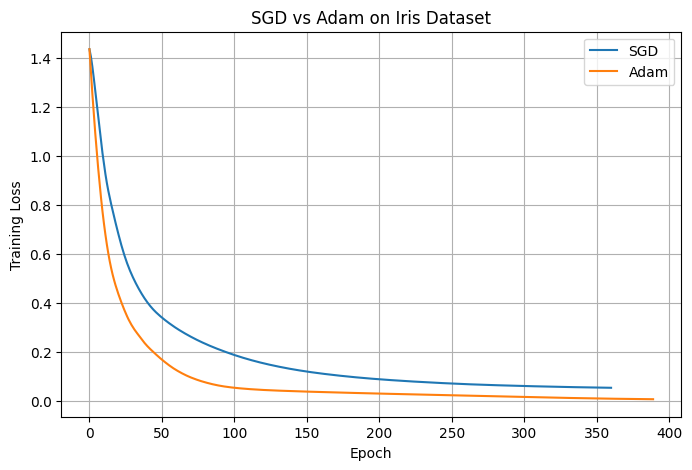

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(results["sgd"]["model"].loss_curve_, label="SGD")
plt.plot(results["adam"]["model"].loss_curve_, label="Adam")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("SGD vs Adam on Iris Dataset")
plt.legend()
plt.grid(True)
plt.savefig("loss_comparison.png", dpi=150)
plt.show()

In [12]:
print("Comparison")
print("Optimizer | Epochs | Final Loss | Test Accuracy")
for name in results:
    m = results[name]["model"]
    print(f"{name.upper():9} | {m.n_iter_:6} | {m.loss_:10.4f} | {results[name]['test_acc']:.4f}")

Comparison
Optimizer | Epochs | Final Loss | Test Accuracy
SGD       |    361 |     0.0528 | 0.9667
ADAM      |    390 |     0.0061 | 0.9667
